## Context-Aware Video Captioning (+ Audio + Semantic Search)- Generating ONE context-aware caption for a short video, using both VISUAL frames and AUDIO speech- Uses pretrained Qwen-VL (through Ollama) for vision + reasoning, and pretrained faster-whisper for speech-to-text- Stores each video's caption as an embedding so we can later search for videos using natural language

### Steps- Imports- Check environment / Ollama- Quick test - can Qwen see an image?- Video input- Frame extraction (OpenCV)- Display sampled frames- Extract audio + transcribe (faster-whisper)- Show transcript- Send frames to Qwen (frame-level observations)- Combine visual observations + transcript -> context reasoning- Final caption- Generate caption embedding- Store video + caption + embedding in the local database- Test semantic search with a natural-language query- Show matching video/caption- Test on another video

### 1. Imports

In [1]:
import os
import json
import cv2
import base64
import requests
import numpy as np
import matplotlib.pyplot as plt

from faster_whisper import WhisperModel
from sentence_transformers import SentenceTransformer

C:\Users\CHINMAY KAPILA\miniconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 2. Check environment / OllamaOllama must be installed and running before this notebook can talk to Qwen.This cell just pings Ollama's local REST API to make sure it is reachable,and lists which models are already pulled.

In [2]:
OLLAMA_URL = "http://localhost:11434"

# A simple GET request to Ollama's local server.
# If this fails, Ollama is either not installed or not running.
try:
    response = requests.get(OLLAMA_URL)
    print("Ollama is running:", response.status_code == 200)
except requests.exceptions.ConnectionError:
    print("Could not reach Ollama. Make sure it is installed and running.")

Ollama is running: True


In [3]:
# List the models already pulled on this machine.
# (Same as running `ollama list` in a terminal.)
tags_response = requests.get(OLLAMA_URL + "/api/tags")

installed_models = [
    m["name"] for m in tags_response.json()["models"]
]

print("Installed models:")

for m in installed_models:
    print(" -", m)

Installed models:
 - qwen3-vl:8b
 - mxbai-embed-large:latest
 - gemma2:2b


### 3. Quick test - can Qwen actually see an image?

In [5]:
VLM_MODEL = "qwen3-vl:8b"


def image_to_base64(path):
    with open(path, "rb") as f:
        return base64.b64encode(f.read()).decode("utf-8")


# Point this to an actual image on your laptop.
test_image_path = r"C:\Users\CHINMAY KAPILA\Downloads\Resume.jpeg"


test_response = requests.post(
    OLLAMA_URL + "/api/chat",
    json={
        "model": VLM_MODEL,
        "messages": [
            {
                "role": "user",
                "content": "Describe this image.",
                "images": [image_to_base64(test_image_path)],
            }
        ],
        "stream": False,
    },
)


print(test_response.json()["message"]["content"])

This image displays a **professional resume** for **Chinmay Kapila**, a B.Tech Computer Science and Engineering student. The resume uses a **two-column layout** on a white background with black text, organized into clear sections, each marked with a simple icon:  

### **Left Column (Personal Details & Proficiencies)**  
- **Name & Title**: Prominently features “Chinmay Kapila” followed by “B.Tech Computer Science and Engineering Student.”  
- **Personal Info**: Includes a phone number (+91 7982986410) and email (chinmay25102006@gmail.com).  
- **Skills**: Lists core competencies with **proficiency bars** (visual indicators of expertise):  
  - *Full proficiency*: Time management, Leadership, Adaptability, Python.  
  - *Medium proficiency*: Data Analyst, Machine Learning.  
- **Languages**: Highlights Hindi (full proficiency) and English (medium proficiency) with matching bars.  

### **Right Column (Professional Summary & Experience)**  
- **Summary**: A concise overview emphasizing 

### 4. Video input

In [9]:
# Path to the short video we want to caption.
VIDEO_PATH = "sample_video.mp4"

cap = cv2.VideoCapture("C:/Users/CHINMAY KAPILA/OneDrive/Videos/Screen Recordings/Screen Recording 2026-07-22 164650.mp4")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
duration_seconds = total_frames / fps if fps else 0

cap.release()

print(f"FPS: {fps}")
print(f"Total frames: {total_frames}")
print(f"Duration: {duration_seconds:.1f} seconds")

FPS: 30.0
Total frames: 1267
Duration: 42.2 seconds


### 5. Frame extraction (OpenCV)We do NOT process every frame - neighbouring frames look almost identical,so that would waste time without adding useful information. Instead wesample a small, evenly spaced set of frames across the video.

In [10]:
MIN_FRAMES = 5
MAX_FRAMES = 15


def sample_frames(video_path):
    cap = cv2.VideoCapture(video_path)

    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_seconds = total_frames / fps if fps else 0

    # Roughly one frame per second of video,
    # clamped to a sensible range.
    num_frames = int(duration_seconds)
    num_frames = max(MIN_FRAMES, min(MAX_FRAMES, num_frames))

    frame_indices = [
        int(i * total_frames / num_frames)
        for i in range(num_frames)
    ]

    frames = []

    for idx in frame_indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        success, frame = cap.read()

        if success:
            frames.append(frame)

    cap.release()

    return frames


frames = sample_frames("C:/Users/CHINMAY KAPILA/OneDrive/Videos/Screen Recordings/Screen Recording 2026-07-22 164650.mp4")

print(f"Sampled {len(frames)} frames.")

Sampled 15 frames.


### 6. Display sampled frames\n\nLet's look at exactly what will be sent to Qwen.

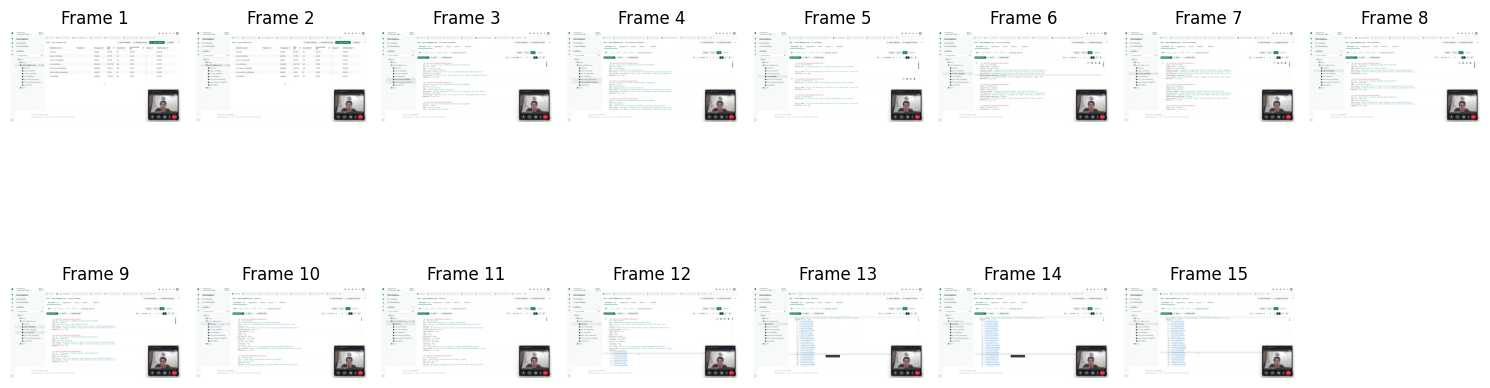

In [11]:
plt.figure(figsize=(15, 6))

for i, frame in enumerate(frames):
    rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.subplot(2, (len(frames) + 1) // 2, i + 1)
    plt.imshow(rgb_frame)
    plt.title(f"Frame {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### 7. Extract audio + transcribe (faster-whisper)faster-whisper can read the audio track straight out of a video file(it uses ffmpeg internally), so there is no separate "extract audio"step needed in our code - we just point it at the video file.We use the small "base" Whisper model on CPU. This keeps the GPU freefor Qwen and is fast enough for short clips. If the video has no audio,or transcription fails for any reason, we fall back to an emptytranscript so the rest of the pipeline still works using vision only.

In [13]:
# Loaded once - reused for every video.
whisper_model = WhisperModel(
    "base",
    device="cpu",
    compute_type="int8"
)


def transcribe_audio(video_path):
    try:
        segments, _ = whisper_model.transcribe(
            video_path,
            beam_size=1
        )

        text = " ".join(
            segment.text.strip()
            for segment in segments
        )

        return text.strip()

    except Exception as e:
        print(
            "Could not transcribe audio, continuing with visual only:",
            e
        )
        return ""


transcript = transcribe_audio("C:/Users/CHINMAY KAPILA/OneDrive/Videos/Screen Recordings/Screen Recording 2026-07-22 164650.mp4")

### 8. Show transcript

In [14]:
print("Transcript:", transcript if transcript else "(no speech detected)")

Transcript: Our vector data is to trusted cyber security information from multiple sources like the MIT Area attack and the MIT TRE-PRE attack which contains the attacker techniques, CVE, POM and vulnerability exposures and the CIS-KEV, known exploited vulnerabilities which contain the vulnerabilities that are actively exploited. CAPEC which describes the common attack patterns and the certain advisories, the cyber security advisories which provide India-specific threat intelligence. Each document is converted into an embedding array of 384 decimal values which are stored in MongoDB enabling semantics search through vector similarity instead of simple keyword matching. This allows the system to quickly retrieve the most relevant cyber security knowledge.


### 9. Send frames to Qwen - frame-level observationsEach frame is sent to Qwen on its own, with a narrow prompt that only asks"what do you see in THIS image". We deliberately do not ask Qwen to guesswhat happens before/after here - that reasoning happens later, once we haveall the observations (and the transcript) together.

In [15]:
def frame_to_base64_jpg(frame):
    success, buffer = cv2.imencode(".jpg", frame)

    return base64.b64encode(buffer).decode("utf-8")


def describe_frame(frame):
    image_b64 = frame_to_base64_jpg(frame)

    prompt = (
        "Describe only what is visually present in this single image "
        "in one short sentence. Mention people, objects, and actions "
        "you can actually see. Do not guess what happened before or "
        "after this image."
    )

    response = requests.post(
        OLLAMA_URL + "/api/chat",
        json={
            "model": VLM_MODEL,
            "messages": [
                {
                    "role": "user",
                    "content": prompt,
                    "images": [image_b64]
                }
            ],
            "stream": False,
        },
    )

    return response.json()["message"]["content"].strip()

In [16]:
observations = []

for i, frame in enumerate(frames):
    obs = describe_frame(frame)
    observations.append(obs)

    print(f"Frame {i + 1}: {obs}")

Frame 1: A MongoDB Data Explorer screen displays a list of collections (e.g., advisories, capec_embeddings) with storage and document details, alongside a Google Meet window showing a person named chinmay kapila.
Frame 2: The image displays a MongoDB Data Explorer interface with listed data collections (e.g., advisories, capec_embeddings) showing storage, document, and index metrics, alongside a Google Meet video call window in the bottom right corner featuring a person named "chinmay kapila".
Frame 3: The image shows a MongoDB Data Explorer interface displaying "mitre_attack_embeddings" documents with STIX and MITRE identifiers alongside a Google Meet window showing a person named "chinmay kapila" in the bottom-right corner.
Frame 4: A MongoDB Data Explorer interface shows document data for "mitre_preattack_embeddings" with fields like stix_id and mitre_id, while a Google Meet window displaying a person named chinmay kapila appears on the right side of the screen.
Frame 5: The image s

### 10. Combine visual observations + transcript -> context reasoningThis is the most important part of the project: instead of justconcatenating the per-frame captions, we give Qwen the FULL picture -what it saw (in order) AND what was said - and ask it to reason aboutwhat actually happened over time.

In [17]:
numbered_observations = "\n".join(
    f"Frame {i + 1}: {obs}"
    for i, obs in enumerate(observations)
)

reasoning_prompt = (
    "VISUAL OBSERVATIONS (in chronological order):\n"
    f"{numbered_observations}\n\n"
    
    "AUDIO TRANSCRIPT (what was said during the video):\n"
    f"{transcript if transcript else '(no speech detected)'}\n\n"
    
    "Using the visual observations AND the audio transcript together, "
    "describe the overall event that took place across the video in ONE "
    "clear sentence. Focus on how things changed over time. If the "
    "transcript adds useful context (like the person's intention), "
    "include it naturally. Do not just list the frames or repeat the "
    "transcript word for word - explain the story as a single connected "
    "sentence."
)

reasoning_response = requests.post(
    OLLAMA_URL + "/api/chat",
    json={
        "model": VLM_MODEL,
        "messages": [
            {
                "role": "user",
                "content": reasoning_prompt
            }
        ],
        "stream": False,
    },
)

final_caption = reasoning_response.json()["message"]["content"].strip()

### 11. Final caption

In [18]:
print("Final Context-Aware Caption:")
print(final_caption)

Final Context-Aware Caption:
The video depicts a continuous screen recording where chinmay kapila's Google Meet call remains visible while the MongoDB Data Explorer interface systematically shifts focus from general collections like `advisories` and `capec_embeddings` to increasingly specific cybersecurity datasets—first showcasing MITRE attack patterns (`mitre_attack_embeddings`, `mitre_preattack_embeddings`), then CVEs (`cve_embeddings`), CIS-KEV exploits (`cisa_kev_embeddings`), and finally detailed advisories (`cyber_intelligence_rag`), all while the narrator explains that this vectorized data, converted into 384-dimensional embeddings from trusted sources like MITRE, CVE, and CIS-KEV, enables semantic search for relevant security knowledge instead of keyword matching.


### 12. Generate caption embeddingWe turn the FINAL CAPTION (not the raw video or frames) into a vectorusing a small pretrained sentence-embedding model. This vector is whatlets us later search for videos using natural language.

In [19]:
# Loaded once - reused for every caption and every search query.
embedder = SentenceTransformer("all-MiniLM-L6-v2")


def embed_text(text):
    return embedder.encode(text).tolist()


caption_embedding = embed_text(final_caption)

print("Embedding length:", len(caption_embedding))

Loading weights: 100%|█████████████████████████████████████████████████████████████| 103/103 [00:00<00:00, 4597.06it/s]


Embedding length: 384


### 13. Store video + caption + embedding in the local databaseWe keep this extremely simple: a single JSON file (`video_database.json`)holding a list of records, and a `videos/` folder holding the actualvideo files. No database server, no vector database - just a list ofdictionaries on disk.

In [20]:
DB_PATH = "video_database.json"



def load_database():
    if not os.path.exists(DB_PATH):
        return []

    with open(DB_PATH, "r") as f:
        return json.load(f)


def save_database(db):
    with open(DB_PATH, "w") as f:
        json.dump(db, f, indent=2)


def add_video_to_database(video_path, caption, embedding):
    db = load_database()

    video_id = f"video_{len(db) + 1:03d}"

    db.append({
        "video_id": video_id,
        "video_path": video_path,
        "caption": caption,
        "embedding": embedding,
    })

    save_database(db)

    return video_id


video_id = add_video_to_database(
    VIDEO_PATH,
    final_caption,
    caption_embedding
)

print("Stored as:", video_id)

Stored as: video_001


### 14. Test semantic search with a natural-language queryWe embed the user's query the same way we embedded the caption, thencompare it against every stored embedding using cosine similarity.The video with the highest similarity (above a threshold) is returned.

In [28]:
SIMILARITY_THRESHOLD = 0.5

def cosine_similarity(a, b):
    a = np.array(a)
    b = np.array(b)

    return float(
        np.dot(a, b)
        / (np.linalg.norm(a) * np.linalg.norm(b))
    )


def search_videos(query, threshold=SIMILARITY_THRESHOLD):
    db = load_database()

    if not db:
        return None

    query_embedding = embed_text(query)

    scored = [
        (
            rec,
            cosine_similarity(query_embedding, rec["embedding"])
        )
        for rec in db
    ]

    best_record, best_score = max(
        scored,
        key=lambda pair: pair[1]
    )

    if best_score >= threshold:
        return best_record, best_score

    return None

In [29]:
# Try a natural-language query related to the video we just stored.
query = "a video showing someone explaining about cybsecurity datasets as vector embeddings in MongoDB for semantic search"

result = search_videos(query)

if result:
    record, score = result

    print(f"Match found (similarity={score:.2f}):")
    print("Video:", record["video_path"])
    print("Caption:", record["caption"])
else:
    print("No matching video found in the database.")

Match found (similarity=0.58):
Video: sample_video.mp4
Caption: The video depicts a continuous screen recording where chinmay kapila's Google Meet call remains visible while the MongoDB Data Explorer interface systematically shifts focus from general collections like `advisories` and `capec_embeddings` to increasingly specific cybersecurity datasets—first showcasing MITRE attack patterns (`mitre_attack_embeddings`, `mitre_preattack_embeddings`), then CVEs (`cve_embeddings`), CIS-KEV exploits (`cisa_kev_embeddings`), and finally detailed advisories (`cyber_intelligence_rag`), all while the narrator explains that this vectorized data, converted into 384-dimensional embeddings from trusted sources like MITRE, CVE, and CIS-KEV, enables semantic search for relevant security knowledge instead of keyword matching.


### 15. Show matching video/caption\n\nJust the matched record, printed clearly.

In [30]:
if result:
    record, score = result

    print("video_id  :", record["video_id"])
    print("video_path:", record["video_path"])
    print("caption   :", record["caption"])
    print("similarity:", round(score, 3))
else:
    print("No matching video found in the database.")

video_id  : video_001
video_path: sample_video.mp4
caption   : The video depicts a continuous screen recording where chinmay kapila's Google Meet call remains visible while the MongoDB Data Explorer interface systematically shifts focus from general collections like `advisories` and `capec_embeddings` to increasingly specific cybersecurity datasets—first showcasing MITRE attack patterns (`mitre_attack_embeddings`, `mitre_preattack_embeddings`), then CVEs (`cve_embeddings`), CIS-KEV exploits (`cisa_kev_embeddings`), and finally detailed advisories (`cyber_intelligence_rag`), all while the narrator explains that this vectorized data, converted into 384-dimensional embeddings from trusted sources like MITRE, CVE, and CIS-KEV, enables semantic search for relevant security knowledge instead of keyword matching.
similarity: 0.581


### 16. Test on another videoWrap everything above into one function so it's easy to try on adifferent video without re-running every cell by hand.

In [31]:
def generate_caption(video_path):
    frames = sample_frames(video_path)

    observations = [
        describe_frame(f)
        for f in frames
    ]

    transcript = transcribe_audio(video_path)

    numbered = "\n".join(
        f"Frame {i + 1}: {o}"
        for i, o in enumerate(observations)
    )

    prompt = (
        "VISUAL OBSERVATIONS (in chronological order):\n"
        f"{numbered}\n\n"
        "AUDIO TRANSCRIPT (what was said during the video):\n"
        f"{transcript if transcript else '(no speech detected)'}\n\n"
        "Using the visual observations AND the audio transcript together, "
        "describe the overall event that took place across the video in "
        "ONE clear sentence. Focus on how things changed over time. Do not "
        "just list the frames or repeat the transcript word for word."
    )

    response = requests.post(
        OLLAMA_URL + "/api/chat",
        json={
            "model": VLM_MODEL,
            "messages": [
                {
                    "role": "user",
                    "content": prompt
                }
            ],
            "stream": False,
        },
    )

    caption = response.json()["message"]["content"].strip()

    return caption, len(frames), transcript

In [32]:
# Try it on a second video, then store it too so search has more than one option.
second_video_path = "C:/Users/CHINMAY KAPILA/OneDrive/Videos/Screen Recordings/Screen Recording 2026-07-22 165507.mp4"

caption, num_frames, transcript = generate_caption(
    second_video_path
)

print(f"Frames analyzed: {num_frames}")
print(
    "Transcript:",
    transcript if transcript else "(no speech detected)"
)
print("Caption:", caption)

embedding = embed_text(caption)

video_id = add_video_to_database(
    second_video_path,
    caption,
    embedding
)

print("Stored as:", video_id)

Frames analyzed: 15
Transcript: When a user submits a query, it is converted into an embedding and is compared with the vector loading the database using the design similarity. The most relevant documents are then retrieved in class to our LLM through a RAP pipeline, allowing it to generate accurate and explainable cybersecurity responses.
Caption: The video depicts a dynamic evolution of a cybersecurity-focused RAG pipeline, beginning with foundational components like vector search and embedding generation (Frames 1–2) and progressively integrating specific threat intelligence databases (CVE, KEV, MITRE, Cert IN) while visually refining the workflow through color-coded stages and explicit data flow (Frames 3–15), ultimately demonstrating how user queries are transformed via cosine similarity into actionable, explainable security responses through the LLM—culminating in a fully operational system that continuously updates its knowledge base.
Stored as: video_002
